<a href="https://colab.research.google.com/github/eyupdemirdag/promptest/blob/main/Prompt_Engineering_on_GSM8K.ipynb" target="_parent"><img src="https://colab.research.google.com/assets/colab-badge.svg" alt="Open In Colab"/></a>

Please see the following paper for :more informartion about this code:

 Astle Travasso, D.; Taherkhani, A. **Evaluating Prompt Engineering Techniques for LLaMA-3: A Study of Zero-Shot, Few-Shot, and Chain-of-Thought Prompts Across Reasoning and Classification Tasks**. Information 2026, 17, 920. https://doi.org/10.3390/info17090920

In [17]:
from huggingface_hub import login
from google.colab import userdata

try:
    # Retrieve your Hugging Face token from the Colab Secrets manager
    hf_token = userdata.get('HF_TOKEN')
    if hf_token:
        login(token=hf_token)
        print("Successfully logged in to Hugging Face using your HF_TOKEN secret!")
    else:
        print("Error: HF_TOKEN not found in your Secrets. Please click the 🔑 icon on the left panel, add a secret named HF_TOKEN, and toggle on 'Notebook access'.")
except Exception as e:
    print(f"An error occurred during authentication: {e}")

Successfully logged in to Hugging Face using your HF_TOKEN secret!


In [18]:
# === [1] Install Required Libraries ===
!pip install -q transformers datasets accelerate bitsandbytes peft


In [19]:
# === [1b] Install Required Libraries ===
#if you get pip dependency errors run it again

!pip install --upgrade datasets transformers

In [21]:
import torch
from datasets import load_dataset
from transformers import (
    AutoTokenizer, AutoModelForCausalLM,
    BitsAndBytesConfig, pipeline
)
from sklearn.metrics import f1_score
import matplotlib.pyplot as plt
from collections import Counter
from tqdm import tqdm
import numpy as np
import re

# === [3] Model Configuration ===
# Switching to Qwen 2.5 7B Instruct which is open-access and excellent at math
model_id = "Qwen/Qwen2.5-7B-Instruct"

bnb_config = BitsAndBytesConfig(
    load_in_4bit=True,
    bnb_4bit_use_double_quant=True,
    bnb_4bit_quant_type="nf4",
    bnb_4bit_compute_dtype=torch.float16
)

tokenizer = AutoTokenizer.from_pretrained(model_id)
tokenizer.pad_token = tokenizer.eos_token

model = AutoModelForCausalLM.from_pretrained(
    model_id,
    device_map="auto",
    quantization_config=bnb_config,
    torch_dtype=torch.float16
)

text_generator = pipeline(
    "text-generation",
    model=model,
    tokenizer=tokenizer,
    max_new_tokens=164,
    temperature=0.2,
    pad_token_id=tokenizer.eos_token_id
)

config.json:   0%|          | 0.00/663 [00:00<?, ?B/s]

tokenizer_config.json:   0%|          | 0.00/7.30k [00:00<?, ?B/s]

vocab.json:   0%|          | 0.00/2.78M [00:00<?, ?B/s]

merges.txt:   0%|          | 0.00/1.67M [00:00<?, ?B/s]

tokenizer.json:   0%|          | 0.00/7.03M [00:00<?, ?B/s]

[transformers] `torch_dtype` is deprecated! Use `dtype` instead!


model.safetensors.index.json:   0%|          | 0.00/27.8k [00:00<?, ?B/s]

Reconstructing (incomplete total...): |          |  0.00B /  0.00B            

Fetching 4 files:   0%|          | 0/4 [00:00<?, ?it/s]

Loading weights:   0%|          | 0/339 [00:00<?, ?it/s]

generation_config.json:   0%|          | 0.00/243 [00:00<?, ?B/s]

In [22]:
# === [4] Load GSM8K Test Subset ===
gsm8k = load_dataset("openai/gsm8k", "main")
#test_data = gsm8k["test"].select(range(350))
test_data = gsm8k["test"].select(range(36))

test_samples = [{"question": row["question"], "answer": row["answer"]} for row in test_data]

README.md:   0%|          | 0.00/7.93k [00:00<?, ?B/s]

main/train-00000-of-00001.parquet: reconstructing file:   0%|          |  0.00B / 2.31MB            

main/train-00000-of-00001.parquet: downloading bytes:           |  0.00B            

main/test-00000-of-00001.parquet: reconstructing file:   0%|          |  0.00B /  419kB            

main/test-00000-of-00001.parquet: downloading bytes:           |  0.00B            

Generating train split:   0%|          | 0/7473 [00:00<?, ? examples/s]

Generating test split:   0%|          | 0/1319 [00:00<?, ? examples/s]

<>:65: SyntaxWarning: invalid escape sequence '\s'
<>:161: SyntaxWarning: invalid escape sequence '\d'
<>:65: SyntaxWarning: invalid escape sequence '\s'
<>:161: SyntaxWarning: invalid escape sequence '\d'
/tmp/ipykernel_917/3910075407.py:65: SyntaxWarning: invalid escape sequence '\s'
  \s* → allows any amount of whitespace after it
/tmp/ipykernel_917/3910075407.py:161: SyntaxWarning: invalid escape sequence '\d'
  \d+ → one or more digits



=== Evaluating: Zero Shot ===


Running Inference: 100%|██████████| 5/5 [06:11<00:00, 74.24s/it]


Accuracy: 16.67% | F1 Score: 28.57% | Solve Rate: 22.22%

=== Evaluating: Few Shot ===


Running Inference: 100%|██████████| 5/5 [06:23<00:00, 76.64s/it]


Accuracy: 2.78% | F1 Score: 5.41% | Solve Rate: 100.00%

=== Evaluating: Cot ===


Running Inference: 100%|██████████| 5/5 [06:11<00:00, 74.31s/it]


Accuracy: 16.67% | F1 Score: 28.57% | Solve Rate: 19.44%


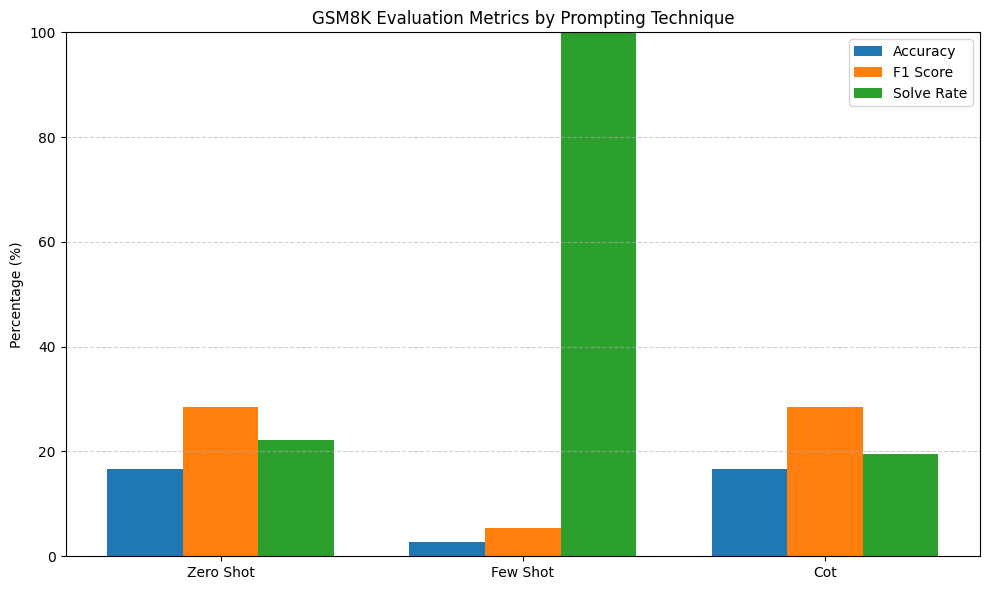

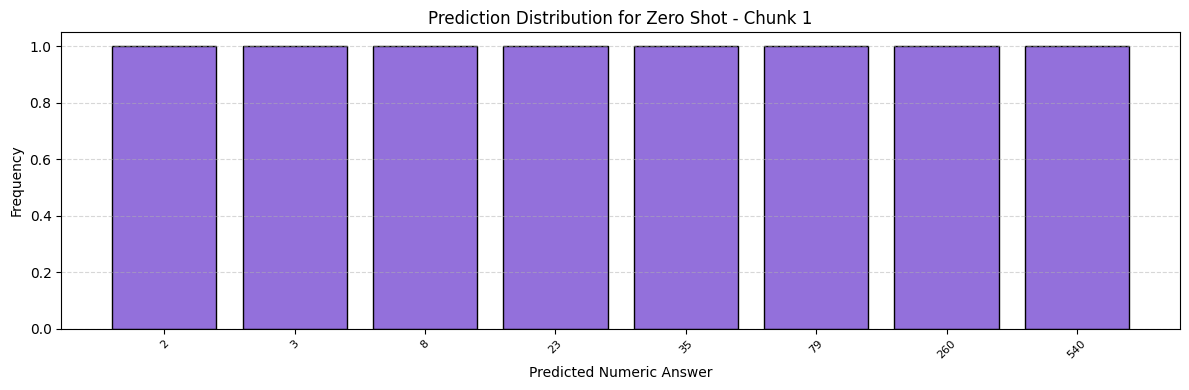

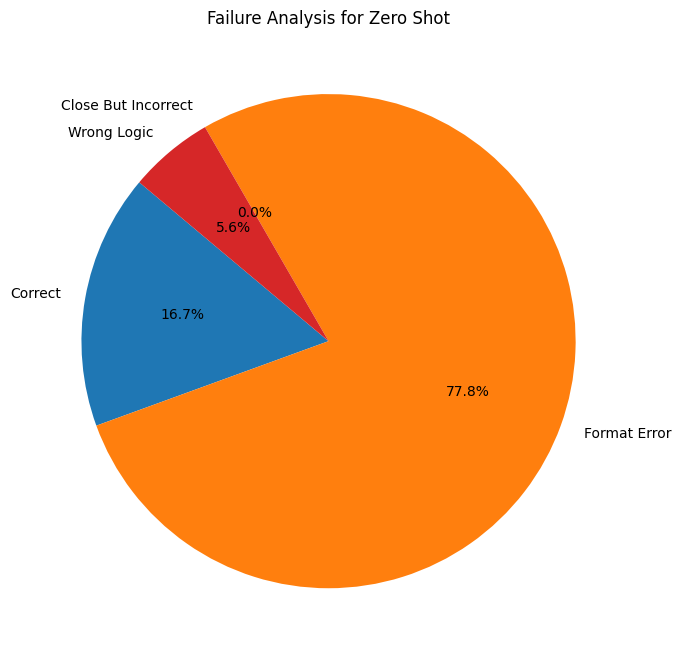

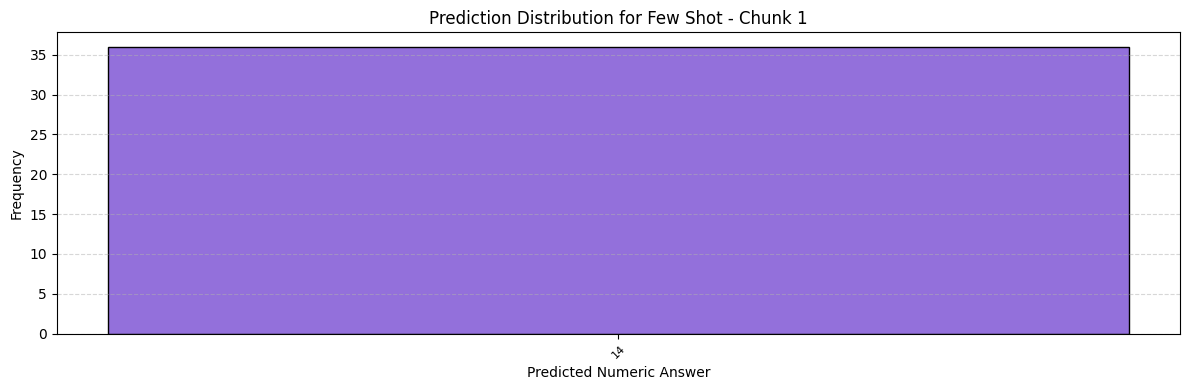

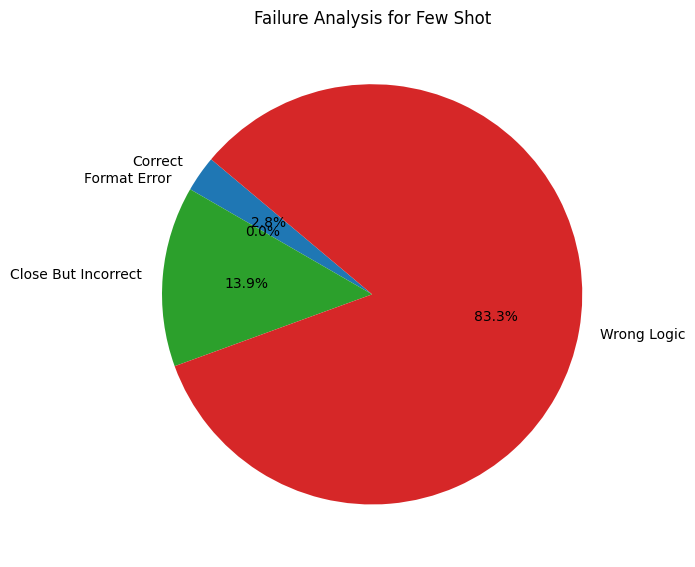

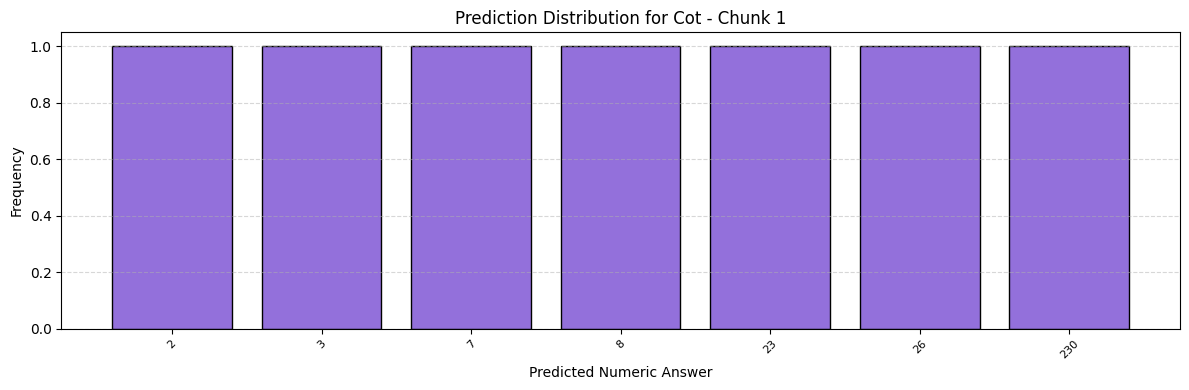

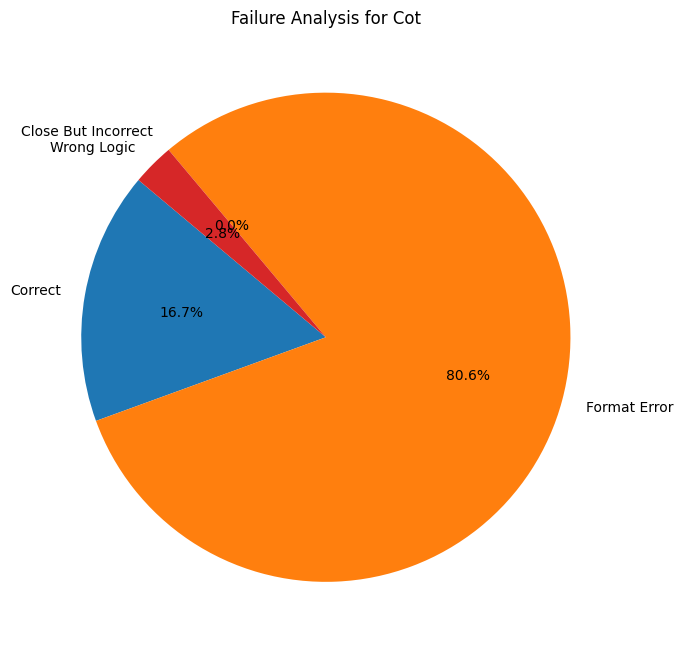

In [23]:
# === [5] Few-Shot Prompt Examples ===
optimized_few_shot_examples = [
    {
        "question": "Alice has 5 boxes. Each box contains 4 pencils. She gives 6 pencils to her friend. How many does she have left?",
        "answer": "5 boxes * 4 pencils = 20 pencils. She gives away 6. 20 - 6 = 14.\n#### 14"
    },
    {
        "question": "A concert ticket costs $15. Jack buys 4 tickets and pays with a $100 bill. How much change does he get?",
        "answer": "4 tickets * $15 = $60. $100 - $60 = $40.\n#### 40"
    },
    {
        "question": "There are 6 rows of chairs with 10 chairs in each row. If 8 chairs are broken, how many usable chairs are there?",
        "answer": "6 * 10 = 60 chairs. 60 - 8 = 52.\n#### 52"
    }
]

# === [6] Prompt Templates ===
def optimized_zero_shot_prompt(example):
    return (
        "You are a math expert. Solve the following word problem step-by-step.\n"
        "Finish with the final answer using the format: #### <number>\n\n"
        f"Q: {example['question']}\nA:"
    )

def optimized_few_shot_prompt(example):
    prompt = (
        "You are a math expert. Solve each problem and provide only the final answer.\n"
        "Format your final answer as: #### <number>\n\n"
    )
    for ex in optimized_few_shot_examples:
        prompt += f"Q: {ex['question']}\nA: {ex['answer']}\n\n"
    prompt += f"Q: {example['question']}\nA:"
    return prompt

def improved_cot_prompt(example):
    return (
        "You are a math reasoning expert.\n"
        "Break down the problem clearly and logically, using one step per line.\n"
        "At the end, provide your final answer on a new line using this format: #### <number>\n\n"
        f"Q: {example['question']}\nA:"
    )

# === [7] Prompt Construction ===
def build_prompts_for_all_techniques(samples, technique):
    prompts, true_answers = [], []
    for sample in samples:
        if technique == "zero_shot":
            prompt = optimized_zero_shot_prompt(sample)
        elif technique == "few_shot":
            prompt = optimized_few_shot_prompt(sample)
        elif technique == "cot":
            prompt = improved_cot_prompt(sample)
        else:
            raise ValueError("Unsupported technique.")
        prompts.append(prompt)
        true_answers.append(sample["answer"].split("####")[-1].strip())
    return prompts, true_answers

# === [8] Answer Extraction ===
def extract_predicted_answer(text):
    match = re.search(r"####\s*([-\d,.]+)", text)
    return match.group(1).replace(",", "") if match else "N/A"
'''
#### → looks for the literal string ####
\s* → allows any amount of whitespace after it
([-\d,.]+) → captures one or more of:
- (negative sign)
\d (digits)
, (comma)
. (decimal point)
Returns the captured number:match.group(1)
.replace(",", ""):So "1,234" becomes "1234".
'''
# === [9] Evaluation Function ===
def run_inference_with_metrics(prompts, true_answers, generator, batch_size=8):
    model_answers, correct_flags, solved_flags = [], [], []

    for i in tqdm(range(0, len(prompts), batch_size), desc="Running Inference"):
        batch = prompts[i:i + batch_size]
        outputs = generator(batch)

        for output, true_ans in zip(outputs, true_answers[i:i + batch_size]):
            generated = output[0]['generated_text']
            pred = extract_predicted_answer(generated)
            model_answers.append(pred)

            try:
                correct = abs(float(pred) - float(true_ans)) < 1e-4
                solved = True
            except:
                correct = False
                solved = pred.strip().isdigit()

            correct_flags.append(correct)
            solved_flags.append(solved)

    accuracy = sum(correct_flags) / len(correct_flags)
    solve_rate = sum(solved_flags) / len(solved_flags)
    f1 = f1_score([1] * len(correct_flags), [1 if x else 0 for x in correct_flags])
    return accuracy * 100, f1 * 100, solve_rate * 100, correct_flags, model_answers

# === [10] Full Evaluation for All Techniques ===
def evaluate_all_final_techniques(samples, generator):
    techniques = ["zero_shot", "few_shot", "cot"]
    results_summary = {}

    for tech in techniques:
        print(f"\n=== Evaluating: {tech.replace('_', ' ').title()} ===")
        prompts, answers = build_prompts_for_all_techniques(samples, tech)
        accuracy, f1, solve_rate, correct_flags, predictions = run_inference_with_metrics(prompts, answers, generator)

        results_summary[tech] = {
            "accuracy": accuracy,
            "f1": f1,
            "solve_rate": solve_rate,
            "correct_flags": correct_flags,
            "model_answers": predictions,
            "true_answers": answers
        }

        print(f"Accuracy: {accuracy:.2f}% | F1 Score: {f1:.2f}% | Solve Rate: {solve_rate:.2f}%")

    return results_summary

# === [11] Run All Evaluations for GSM8K ===
results_summary = evaluate_all_final_techniques(test_samples, text_generator)

# === [12] Bar Chart: Accuracy, F1 Score, Solve Rate ===
def plot_gsm8k_results(results_summary):
    techniques = list(results_summary.keys())
    accuracy = [results_summary[t]["accuracy"] for t in techniques]
    f1_score_vals = [results_summary[t]["f1"] for t in techniques]
    solve_rate = [results_summary[t]["solve_rate"] for t in techniques]

    x = np.arange(len(techniques))
    width = 0.25

    plt.figure(figsize=(10, 6))
    plt.bar(x - width, accuracy, width, label='Accuracy')
    plt.bar(x, f1_score_vals, width, label='F1 Score')
    plt.bar(x + width, solve_rate, width, label='Solve Rate')

    plt.ylabel("Percentage (%)")
    plt.title("GSM8K Evaluation Metrics by Prompting Technique")
    plt.xticks(x, [t.replace("_", " ").title() for t in techniques])
    plt.ylim(0, 100)
    plt.grid(axis='y', linestyle='--', alpha=0.6)
    plt.legend()
    plt.tight_layout()
    plt.show()


# === [13] Prediction Distribution (Sorted & Clean) ===
def plot_prediction_distribution(results_summary, technique, chunk_size=50):
    predictions = results_summary[technique]["model_answers"]
    numeric_preds = [p for p in predictions if re.match(r"^-?\d+(\.\d+)?$", p)]
    '''
    Regular expression breakdown
^ → start of string
-? → optional negative sign
\d+ → one or more digits
(\.\d+)? → optional decimal part
  \. → decimal point
  \d+ → one or more digits after the point
$ → end of string
    '''

    if not numeric_preds:
        print(f"No numeric predictions found for {technique}.")
        return

    counts = Counter(numeric_preds)
    sorted_counts = dict(sorted(counts.items(), key=lambda x: float(x[0])))

    x_vals = list(sorted_counts.keys())
    y_vals = list(sorted_counts.values())

    # Chunked visualization
    num_chunks = (len(x_vals) + chunk_size - 1) // chunk_size
    for i in range(num_chunks):
        start = i * chunk_size
        end = start + chunk_size
        chunk_x = x_vals[start:end]
        chunk_y = y_vals[start:end]

        plt.figure(figsize=(12, 4))
        plt.bar(chunk_x, chunk_y, color='mediumpurple', edgecolor='black')
        plt.title(f"Prediction Distribution for {technique.replace('_', ' ').title()} - Chunk {i+1}")
        plt.xlabel("Predicted Numeric Answer")
        plt.ylabel("Frequency")
        plt.xticks(rotation=45, fontsize=8)
        plt.grid(axis='y', linestyle='--', alpha=0.5)
        plt.tight_layout()
        plt.show()


# === [14] Failure Analysis Pie Chart ===
def plot_failure_analysis_pie(results_summary, technique):
    predictions = results_summary[technique]["model_answers"]
    true_answers = results_summary[technique]["true_answers"]

    categories = {
        "Correct": 0,
        "Format Error": 0,
        "Close But Incorrect": 0,
        "Wrong Logic": 0
    }

    for pred, true in zip(predictions, true_answers):
        try:
            pred_val = float(pred)
            true_val = float(true)
            if abs(pred_val - true_val) < 1e-4:
                categories["Correct"] += 1
            elif abs(pred_val - true_val) < 5:
                categories["Close But Incorrect"] += 1
            else:
                categories["Wrong Logic"] += 1
        except:
            categories["Format Error"] += 1

    plt.figure(figsize=(7, 7))
    plt.pie(categories.values(), labels=categories.keys(), autopct='%1.1f%%', startangle=140)
    plt.title(f"Failure Analysis for {technique.replace('_', ' ').title()}")
    plt.tight_layout()
    plt.show()

plot_gsm8k_results(results_summary)

for technique in ["zero_shot", "few_shot", "cot"]:
    plot_prediction_distribution(results_summary, technique)
    plot_failure_analysis_pie(results_summary, technique)

In [24]:
results_summary

{'zero_shot': {'accuracy': 16.666666666666664,
  'f1': 28.57142857142857,
  'solve_rate': 22.22222222222222,
  'correct_flags': [False,
   True,
   False,
   True,
   False,
   False,
   True,
   False,
   False,
   False,
   False,
   False,
   False,
   False,
   False,
   False,
   False,
   False,
   False,
   False,
   False,
   False,
   False,
   True,
   False,
   False,
   False,
   False,
   False,
   False,
   False,
   False,
   True,
   False,
   True,
   False],
  'model_answers': ['N/A',
   '3',
   'N/A',
   '540',
   'N/A',
   'N/A',
   '260',
   'N/A',
   'N/A',
   'N/A',
   'N/A',
   'N/A',
   'N/A',
   'N/A',
   'N/A',
   'N/A',
   'N/A',
   '79',
   'N/A',
   'N/A',
   'N/A',
   '2',
   'N/A',
   '8',
   'N/A',
   'N/A',
   'N/A',
   'N/A',
   'N/A',
   'N/A',
   'N/A',
   'N/A',
   '35',
   'N/A',
   '23',
   'N/A'],
  'true_answers': ['18',
   '3',
   '70000',
   '540',
   '20',
   '64',
   '260',
   '160',
   '45',
   '460',
   '366',
   '694',
   '13',
   '18',
